In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             RocCurveDisplay, ConfusionMatrixDisplay)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

train = pd.read_csv("student_placement_train.csv")
test = pd.read_csv("student_placement_test.csv")
sample_sub = pd.read_csv("sample_submission.csv")

TARGET = "placed"
ID_COL = "student_id"

print("Train :", train.shape)
print("Test  :", test.shape)
print("Sample:", sample_sub.shape)

Train : (8000, 28)
Test  : (2000, 27)
Sample: (2000, 2)


In [2]:
display(train.head())
train.info()

,student_id,age,gender,cgpa,attendance_percentage,backlogs,coding_score,aptitude_score,communication_score,technical_score,projects_count,major_projects,internships_count,internship_months,certifications_count,hackathons_participated,hackathons_won,coding_platform_score,github_projects,linkedin_score,resume_score,soft_skills_score,leadership_score,extracurricular_score,training_hours,mock_interview_score,preferred_domain,placed
0,STU107218,21,Male,5.75,77.1,0,29.3,39.9,83.0,24.3,0,0,2,8.6,5,0,0,533,0,67.8,58.8,87.5,47.7,59.1,43.8,75.8,Data Science,0
1,STU108292,23,Male,7.14,NaN,0,61.7,63.4,55.3,49.0,4,1,1,3.5,1,1,0,943,5,53.5,77.8,77.9,71.2,34.5,102.3,70.8,Business Analytics,0
2,STU104608,23,Male,7.68,76.0,0,51.6,59.6,46.3,43.3,4,1,1,5.0,3,0,0,487,4,63.6,65.5,55.9,44.3,51.5,96.1,70.8,Business Analytics,0
3,STU105115,24,Male,6.07,75.8,1,24.0,47.5,75.0,65.1,3,0,0,0.0,2,1,0,619,3,65.7,59.8,75.6,90.9,54.4,118.5,91.1,Software Development,0
4,STU101860,20,Male,7.97,74.0,1,33.1,47.4,58.1,64.4,1,0,2,9.9,2,0,0,377,2,75.3,30.6,73.9,45.0,83.0,59.6,77.0,Business Analytics,0


<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 28 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   student_id               8000 non-null   str    
 1   age                      8000 non-null   int64  
 2   gender                   8000 non-null   str    
 3   cgpa                     8000 non-null   float64
 4   attendance_percentage    7794 non-null   float64
 5   backlogs                 8000 non-null   int64  
 6   coding_score             7859 non-null   float64
 7   aptitude_score           7881 non-null   float64
 8   communication_score      7851 non-null   float64
 9   technical_score          7869 non-null   float64
 10  projects_count           8000 non-null   int64  
 11  major_projects           8000 non-null   int64  
 12  internships_count        8000 non-null   int64  
 13  internship_months        7762 non-null   float64
 14  certifications_count     8000 non-n

In [3]:
# Missing value, duplikat, dan statistik
missing = train.isna().sum()
print("Missing value (hanya yang > 0):")
display(missing[missing > 0].sort_values(ascending=False).to_frame("jumlah").assign(
    persen=lambda d: (d["jumlah"] / len(train) * 100).round(2)))

print("Duplikat baris :", train.duplicated().sum())
print("Duplikat ID    :", train[ID_COL].duplicated().sum())
print("ID train & test tumpang tindih:", len(set(train[ID_COL]) & set(test[ID_COL])))

display(train.describe().T.round(2))

Missing value (hanya yang > 0):


,jumlah,persen
linkedin_score,315,3.94
mock_interview_score,295,3.69
training_hours,241,3.01
internship_months,238,2.97
attendance_percentage,206,2.58
resume_score,189,2.36
soft_skills_score,154,1.92
communication_score,149,1.86
coding_score,141,1.76
technical_score,131,1.64


Duplikat baris : 0
Duplikat ID    : 0
ID train & test tumpang tindih: 0


,count,mean,std,min,25%,50%,75%,max
age,8000.0,21.68,1.14,19.0,21.00,22.00,22.00,26.0
cgpa,8000.0,7.58,0.85,5.0,7.00,7.58,8.14,10.0
attendance_percentage,7794.0,81.91,8.82,55.0,76.00,81.95,88.10,100.0
backlogs,8000.0,0.55,0.73,0.0,0.00,0.00,1.00,4.0
coding_score,7859.0,53.16,15.74,15.0,42.40,52.90,63.90,100.0
aptitude_score,7881.0,55.98,14.17,15.0,46.50,55.90,65.50,100.0
communication_score,7851.0,57.91,14.02,20.0,48.35,57.80,67.30,100.0
technical_score,7869.0,54.28,15.53,15.0,43.60,54.30,64.60,100.0
projects_count,8000.0,2.60,1.65,0.0,1.00,2.00,4.00,15.0
major_projects,8000.0,0.90,0.94,0.0,0.00,1.00,1.00,7.0


placed
0    6370
1    1630
Name: count, dtype: int64
placed
0    0.7962
1    0.2037
Name: proportion, dtype: float64


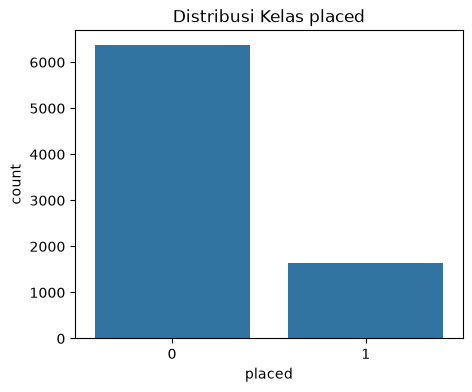

In [4]:
# Distribusi target (cek apakah benar-benar biner dan seberapa timpang)
print(train[TARGET].value_counts())
print(train[TARGET].value_counts(normalize=True).round(4))

plt.figure(figsize=(5, 4))
sns.countplot(x=TARGET, data=train)
plt.title("Distribusi Kelas placed")
plt.show()

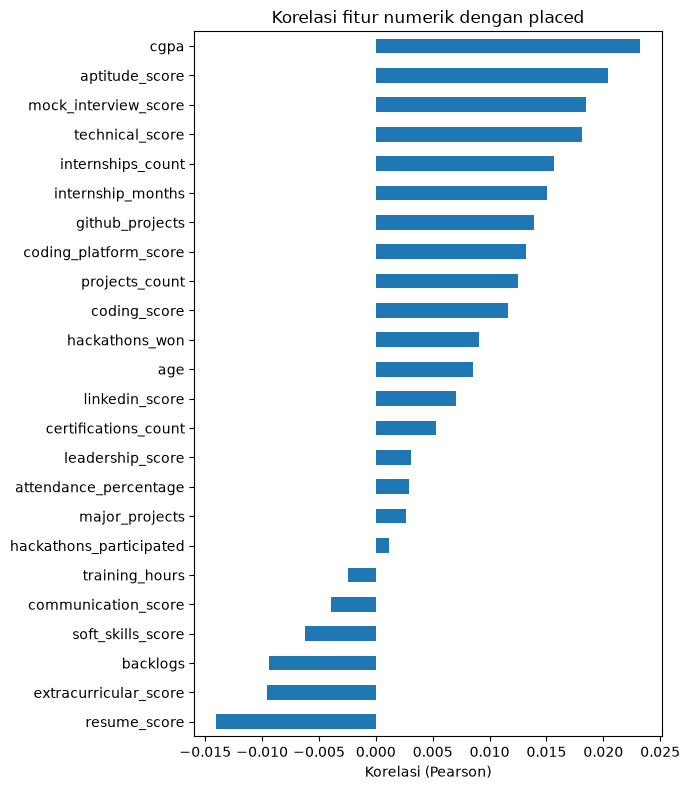

,rasio_placed,jumlah
gender,,
Female,0.210,2961
Male,0.199,4885
Other,0.214,154


,rasio_placed,jumlah
preferred_domain,,
AI/ML,0.212,1413
Business Analytics,0.216,952
Cloud Computing,0.217,946
Cyber Security,0.179,803
Data Science,0.189,1637
Software Development,0.208,2249


In [5]:
num_cols_all = train.drop(columns=[ID_COL, TARGET]).select_dtypes(include=np.number).columns

# Korelasi fitur numerik dengan target
corr = train[list(num_cols_all) + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
plt.figure(figsize=(7, 8))
corr.plot(kind="barh")
plt.title("Korelasi fitur numerik dengan placed")
plt.xlabel("Korelasi (Pearson)")
plt.tight_layout()
plt.show()

# Persentase placed per kategori
for col in ["gender", "preferred_domain"]:
    display(train.groupby(col)[TARGET].agg(["mean", "count"]).round(3)
            .rename(columns={"mean": "rasio_placed", "count": "jumlah"}))

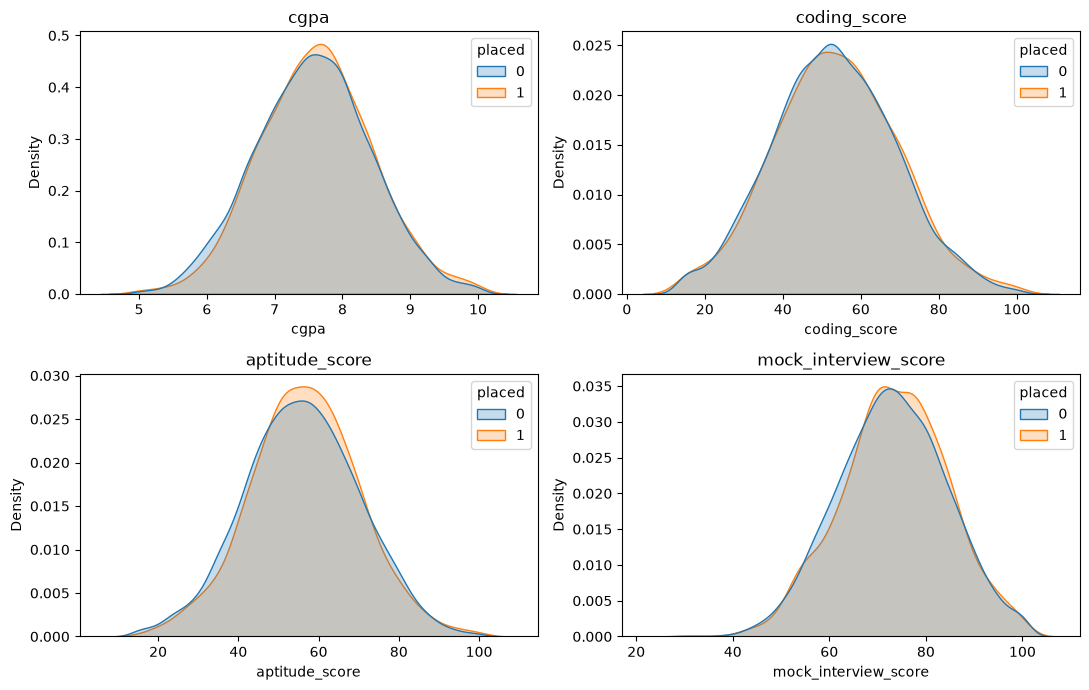

In [6]:
# Distribusi beberapa fitur utama berdasarkan placed
fitur_lihat = ["cgpa", "coding_score", "aptitude_score", "mock_interview_score"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), fitur_lihat):
    sns.kdeplot(data=train, x=col, hue=TARGET, common_norm=False, fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [7]:
X = train.drop(columns=[ID_COL, TARGET])
y = train[TARGET]

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print("Numerik    :", len(num_cols))
print("Kategorikal:", cat_cols)

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Validasi:", X_val.shape)

Numerik    : 24
Kategorikal: ['gender', 'preferred_domain']
Train: (6400, 26) | Validasi: (1600, 26)


In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                        max_iter=200, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "f1": "f1", "precision": "precision", "recall": "recall"}

rows = []
for nama, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", model)])
    hasil = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({
        "Model": nama,
        "ROC-AUC": hasil["test_roc_auc"].mean(),
        "F1": hasil["test_f1"].mean(),
        "Precision": hasil["test_precision"].mean(),
        "Recall": hasil["test_recall"].mean(),
        "Std ROC-AUC": hasil["test_roc_auc"].std(),
    })

hasil_cv = pd.DataFrame(rows).set_index("Model").round(4).sort_values("ROC-AUC", ascending=False)
display(hasil_cv)

,ROC-AUC,F1,Precision,Recall,Std ROC-AUC
Model,,,,,
Logistic Regression,0.5001,0.2842,0.2026,0.4762,0.0139
Random Forest,0.4906,0.0390,0.1716,0.0222,0.0096
Decision Tree,0.4820,0.3053,0.1974,0.6787,0.0212
Gradient Boosting,0.4810,0.0015,0.2000,0.0008,0.0151


In [9]:
fitted = {}
rows = []
for nama, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_val)
    proba = pipe.predict_proba(X_val)[:, 1]
    fitted[nama] = pipe
    rows.append({
        "Model": nama,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred),
        "ROC-AUC": roc_auc_score(y_val, proba),
    })

hasil_val = pd.DataFrame(rows).set_index("Model").round(4).sort_values("ROC-AUC", ascending=False)
display(hasil_val)

# Pembanding: akurasi jika menebak semua 0
print("Akurasi baseline (tebak semua 0):", round((y_val == 0).mean(), 4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Gradient Boosting,0.7962,0.0000,0.0000,0.0000,0.5037
Random Forest,0.7887,0.3000,0.0276,0.0506,0.5010
Decision Tree,0.4469,0.1985,0.5644,0.2937,0.4995
Logistic Regression,0.5219,0.2014,0.4540,0.2790,0.4898


Akurasi baseline (tebak semua 0): 0.7962


Model terbaik: Gradient Boosting
              precision    recall  f1-score   support

Tidak placed       0.80      1.00      0.89      1274
      Placed       0.00      0.00      0.00       326

    accuracy                           0.80      1600
   macro avg       0.40      0.50      0.44      1600
weighted avg       0.63      0.80      0.71      1600



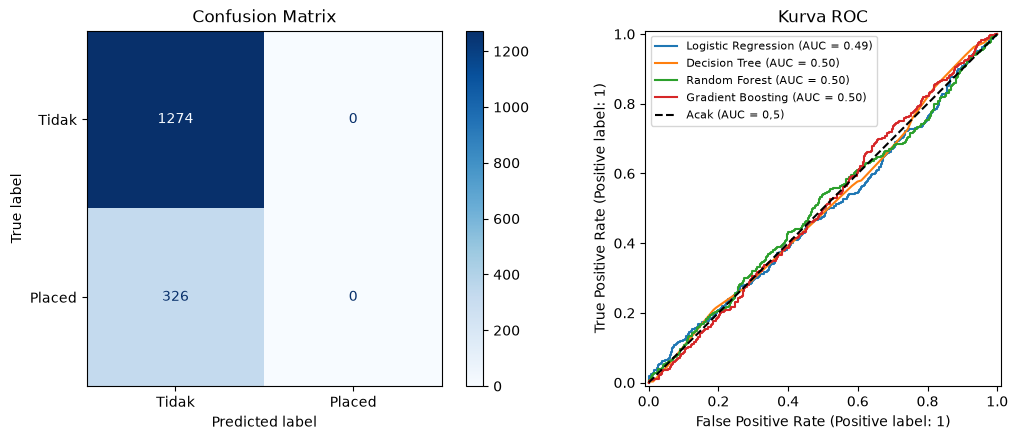

In [10]:
# Model terbaik berdasarkan ROC-AUC validasi
nama_terbaik = hasil_val.index[0]
terbaik = fitted[nama_terbaik]
pred = terbaik.predict(X_val)
print("Model terbaik:", nama_terbaik)
print(classification_report(y_val, pred, target_names=["Tidak placed", "Placed"], zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_val, pred, display_labels=["Tidak", "Placed"],
                                        cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix")
for nama, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_val, y_val, name=nama, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Acak (AUC = 0,5)")
axes[1].set_title("Kurva ROC")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
final_model = Pipeline([("prep", preprocess), ("clf", models[nama_terbaik])])
final_model.fit(X, y)

X_test = test.drop(columns=[ID_COL])[X.columns]   # pastikan urutan kolom sama
proba_test = final_model.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({ID_COL: test[ID_COL], TARGET: proba_test})

# Samakan urutan baris dengan sample_submission
submission = sample_sub[[ID_COL]].merge(submission, on=ID_COL, how="left")

assert submission.shape == sample_sub.shape
assert submission[TARGET].notna().all()

submission.to_csv("submission.csv", index=False)
display(submission.head())
print("Tersimpan: submission.csv")

,student_id,placed
0,STU100015,0.225531
1,STU101530,0.253856
2,STU100235,0.257008
3,STU100564,0.238978
4,STU105655,0.193230


Tersimpan: submission.csv


# README: Dataset Student Placement

## Ringkasan dataset

| Item | Keterangan |
|---|---|
| File | `student_placement_train.csv`, `student_placement_test.csv`, `sample_submission.csv` |
| Jumlah data | Train 8.000 baris, test 2.000 baris |
| Kolom train | 28 kolom: 1 ID (`student_id`), 26 fitur, 1 target (`placed`) |
| Tipe fitur | 24 numerik, 2 kategorikal (`gender`, `preferred_domain`) |
| Target | `placed` |
| Missing value | Ada di 11 kolom numerik (misalnya `linkedin_score`, `mock_interview_score`, `training_hours`) |

Dataset ini berisi profil akademik dan keterampilan mahasiswa (IPK, skor coding, jumlah proyek, magang, sertifikasi, dan sebagainya) beserta status penempatan kerjanya.

## Mengapa ini termasuk klasifikasi biner

1. **Pembelajaran terawasi (supervised).** Setiap baris pada data train sudah punya label `placed`, sehingga model belajar dari pasangan fitur dan label.
2. **Targetnya kategorikal, bukan angka kontinu.** `placed` menyatakan sebuah kelas (mahasiswa mendapat penempatan kerja atau tidak), bukan besaran yang diukur seperti harga atau suhu. Karena itu masalahnya bukan regresi.
3. **Targetnya hanya punya tepat dua nilai.**

| Nilai `placed` | Arti | Jumlah (train) | Persentase |
|---|---|---|---|
| 0 | Tidak placed | 6.370 | 79,6% |
| 1 | Placed | 1.630 | 20,4% |

4. **Kedua kelas saling lepas.** Satu mahasiswa hanya masuk ke salah satu kelas. Tidak ada kelas ketiga, sehingga ini bukan klasifikasi multi-kelas.
5. **Keluaran model berupa keputusan dua pilihan.** Model memprediksi apakah seorang mahasiswa akan placed (1) atau tidak (0), atau probabilitas untuk kelas 1.

## Karakteristik penting

- **Kelas tidak seimbang** (sekitar 80:20). Akurasi saja menyesatkan karena menebak semua 0 sudah menghasilkan akurasi 79,6%. Gunakan ROC-AUC, precision, recall, dan F1, serta pertimbangkan `class_weight="balanced"`.
- `sample_submission.csv` berisi **probabilitas** kelas 1 (bukan label 0/1), sehingga metrik penilaiannya kemungkinan ROC-AUC.
- Kolom `student_id` dibuang dari fitur karena hanya pengenal.

## Hasil baseline (5-fold cross-validation)

| Model | ROC-AUC | F1 |
|---|---|---|
| Logistic Regression | 0,489 | 0,273 |
| Random Forest | 0,483 | 0,038 |
| Gradient Boosting | 0,492 | 0,010 |

ROC-AUC sekitar 0,5 berarti model tidak lebih baik dari tebakan acak. Korelasi tertinggi fitur numerik dengan `placed` hanya 0,023, dan persentase placed hampir sama antar kategori `gender` maupun `preferred_domain`. Artinya, fitur pada dataset ini hampir tidak membawa informasi untuk memprediksi `placed`. Temuan ini adalah sifat datanya, bukan kesalahan kode.